## Import libraries


In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

## Load the datasets

In [2]:
prepared_data = joblib.load("../data/processed/prepared_data.pkl")

X_train = prepared_data["X_train"]
X_test = prepared_data["X_test"]
y_train = prepared_data["y_train"]
y_test = prepared_data["y_test"]

In [3]:
# Confirm that everything loaded correctly
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 30)
X_test: (1409, 30)
y_train: (5634,)
y_test: (1409,)


## Build Logistic Regression

In [4]:
# Create the model
log_model = LogisticRegression(random_state=42)

In [5]:
# Train the model
log_model.fit(X_train, y_train)

LogisticRegression(random_state=42)

In [6]:
# Make prediction
y_pred_log = log_model.predict(X_test)
print(y_pred_log[:10])

[0 1 0 0 0 1 0 0 0 0]


In [7]:
# Evaluate model accuracy
accuracy = accuracy_score(y_test, y_pred_log)

print("Logistic Regression Accuracy:", accuracy)

Logistic Regression Accuracy: 0.8062455642299503


In [8]:
# Classification report
print(classification_report(y_test, y_pred_log))

              precision    recall  f1-score   support

           0       0.85      0.90      0.87      1035
           1       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [9]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_log)

print(cm)

[[927 108]
 [165 209]]


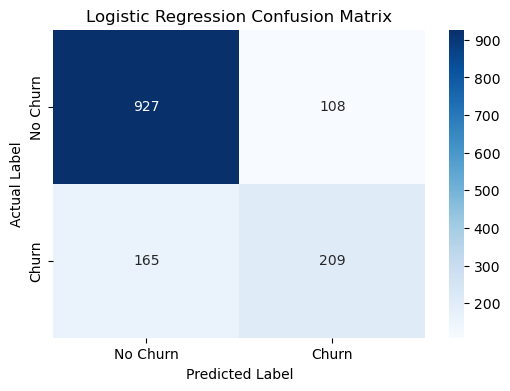

In [10]:
# Visualization
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Logistic Regression Confusion Matrix")

plt.show()

### Logistic Regression – Model Evaluation Summary

Logistic Regression was implemented as the first classification algorithm for the Customer Churn Prediction project. The model was trained using 5,634 training observations and evaluated using 1,409 testing observations, with 30 input features.

The model achieved an accuracy of **80.62%**, indicating that it correctly classified approximately 81% of the customers in the test dataset.

The classification report produced the following results:

- **Class 0 (No Churn):** Precision of 85%, Recall of 90%, and F1-score of 87%.
- **Class 1 (Churn):** Precision of 66%, Recall of 56%, and F1-score of 60%.
- **Macro Average F1-score:** 74%.
- **Weighted Average F1-score:** 80%.

The confusion matrix produced the following results:

- True Negative (TN): 927
- False Positive (FP): 108
- False Negative (FN): 165
- True Positive (TP): 209

The results indicate that Logistic Regression performs better at identifying customers who stay with the company than customers who leave. Although the model achieved a reasonable accuracy of 80.62%, its recall for the churn class was relatively low at 56%, meaning it failed to identify a considerable number of customers who actually churned.

**Conclusion:** Logistic Regression provides a reasonable baseline for the Customer Churn Prediction project. However, its ability to identify customers likely to churn requires improvement. Other classification algorithms will therefore be implemented and evaluated to determine whether they can achieve better predictive performance.

## Build KNN 

In [11]:
# Create the model
knn_model = KNeighborsClassifier(n_neighbors=5)

In [12]:
# Train the model
knn_model.fit(X_train, y_train)

KNeighborsClassifier()

In [13]:
# Make prediction
y_pred_knn = knn_model.predict(X_test)

print(y_pred_knn[:10])

[0 1 0 0 0 1 1 0 0 1]


In [14]:
# Evaluate KNN accuracy
accuracy_knn = accuracy_score(y_test, y_pred_knn)

print("KNN Accuracy:", accuracy_knn)

KNN Accuracy: 0.7629524485450674


In [15]:
# Classification report
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

           0       0.84      0.84      0.84      1035
           1       0.55      0.55      0.55       374

    accuracy                           0.76      1409
   macro avg       0.70      0.70      0.70      1409
weighted avg       0.76      0.76      0.76      1409



In [16]:
# Confusion matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)

print(cm_knn)

[[869 166]
 [168 206]]


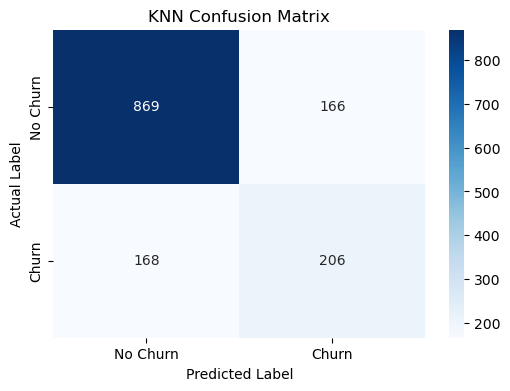

In [17]:
# Visualize the Confusion Matrix
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_knn,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("KNN Confusion Matrix")

plt.show()

### K-Nearest Neighbors (KNN) – Model Evaluation Summary

K-Nearest Neighbors (KNN) was implemented as the second classification algorithm for the Customer Churn Prediction project. The model was trained using 5,634 training observations and evaluated using 1,409 testing observations, with 30 input features.

The KNN model was configured with 5 nearest neighbors (`n_neighbors=5`) and achieved an accuracy of **76.30%**.

The classification report produced the following results:

- **Class 0 (No Churn):** Precision of 84%, Recall of 84%, and F1-score of 84%.
- **Class 1 (Churn):** Precision of 55%, Recall of 55%, and F1-score of 55%.
- **Macro Average F1-score:** 70%.
- **Weighted Average F1-score:** 76%.

The confusion matrix produced the following results:

- True Negative (TN): 869
- False Positive (FP): 166
- False Negative (FN): 168
- True Positive (TP): 206

The results indicate that KNN performs better at identifying customers who stay with the company than customers who leave. Its recall for the churn class was 55%, meaning it identified approximately 55% of actual churners while failing to identify the remaining 45%.

**Conclusion:** KNN achieved an accuracy of 76.30%, which is lower than the 80.62% achieved by Logistic Regression. It also recorded a lower F1-score for the churn class (55% compared with 60% for Logistic Regression). Therefore, Logistic Regression currently performs better than KNN based on the evaluation results. Further classification algorithms will be explored to identify a model with better predictive performance.

## Build SVM

In [18]:
# Create the model
svm_model = SVC(kernel="rbf", random_state=42)

In [19]:
# Train the model
svm_model.fit(X_train, y_train)

SVC(random_state=42)

In [20]:
# Make prediction
y_pred_svm = svm_model.predict(X_test)

print(y_pred_svm[:10])

[0 1 0 0 0 1 0 0 0 0]


In [21]:
# Evaluate SVM accuracy
accuracy_svm = accuracy_score(y_test, y_pred_svm)

print("SVM Accuracy:", accuracy_svm)

SVM Accuracy: 0.794889992902768


In [22]:
# Classification report
print(classification_report(y_test, y_pred_svm))

              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1035
           1       0.65      0.48      0.55       374

    accuracy                           0.79      1409
   macro avg       0.74      0.69      0.71      1409
weighted avg       0.78      0.79      0.78      1409



In [23]:
# Confusion Matrix
cm_svm = confusion_matrix(y_test, y_pred_svm)

print(cm_svm)

[[940  95]
 [194 180]]


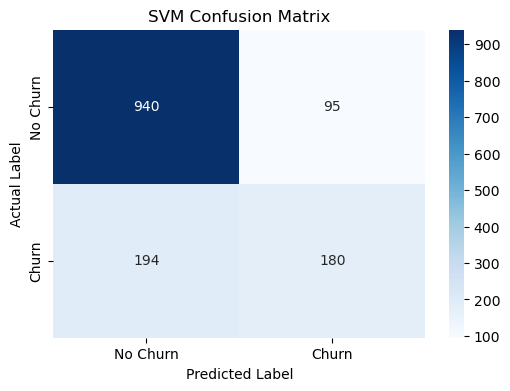

In [24]:
# Visualize the Confusion Matrix

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("SVM Confusion Matrix")

plt.show()

### Support Vector Machine (SVM) – Model Evaluation Summary

Support Vector Machine (SVM) was implemented as the third classification algorithm for the Customer Churn Prediction project. The model was trained using 5,634 training observations and evaluated using 1,409 testing observations, with 30 input features.

The SVM model was configured with the Radial Basis Function (RBF) kernel and achieved an accuracy of **79.49%**.

The classification report produced the following results:

- **Class 0 (No Churn):** Precision of 83%, Recall of 91%, and F1-score of 87%.
- **Class 1 (Churn):** Precision of 65%, Recall of 48%, and F1-score of 55%.
- **Macro Average F1-score:** 71%.
- **Weighted Average F1-score:** 78%.

The confusion matrix produced the following results:

- True Negative (TN): 940
- False Positive (FP): 95
- False Negative (FN): 194
- True Positive (TP): 180

The results indicate that SVM performs very well at identifying customers who stay with the company but struggles to identify customers who leave. Its recall for the churn class was 48%, meaning it identified approximately 48% of actual churners while failing to identify the remaining 52%.

**Conclusion:** SVM achieved an accuracy of 79.49%, which is slightly lower than Logistic Regression's 80.62% but higher than KNN's 76.30%. However, Logistic Regression currently performs better in identifying customers who churn, based on its higher churn recall and F1-score. Further classification algorithms will be explored to determine whether predictive performance can be improved.

## Build Artificial Neural Network (ANN)

In [25]:
# Create the model
ann_model = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42
)

In [26]:
# Train the model
ann_model.fit(X_train, y_train)

MLPClassifier(max_iter=1000, random_state=42)

In [27]:
# Make prediction
y_pred_ann = ann_model.predict(X_test)

print(y_pred_ann[:10])

[0 1 0 0 0 1 1 0 0 0]


In [28]:
# Evaluate ANN Accuracy
accuracy_ann = accuracy_score(y_test, y_pred_ann)

print("ANN Accuracy:", accuracy_ann)

ANN Accuracy: 0.7693399574166075


In [29]:
# Classification report
print(classification_report(y_test, y_pred_ann))

              precision    recall  f1-score   support

           0       0.83      0.86      0.85      1035
           1       0.57      0.51      0.54       374

    accuracy                           0.77      1409
   macro avg       0.70      0.69      0.69      1409
weighted avg       0.76      0.77      0.76      1409



In [30]:
# Confusion matrix
cm_ann = confusion_matrix(y_test, y_pred_ann)

print(cm_ann)

[[893 142]
 [183 191]]


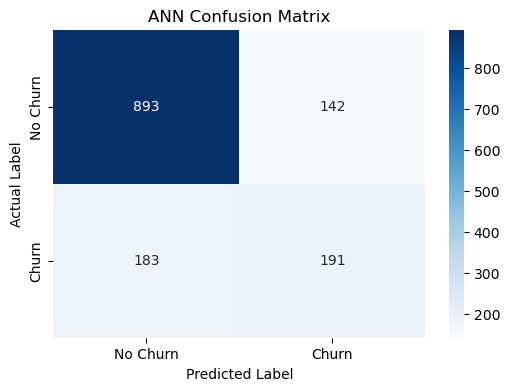

In [31]:
# Visualize the Confusion Matrix

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_ann,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ANN Confusion Matrix")

plt.show()

### Artificial Neural Network (ANN) – Model Evaluation Summary

Artificial Neural Network (ANN) was implemented as the fourth classification algorithm for the Customer Churn Prediction project. The model was trained using 5,634 training observations and evaluated using 1,409 testing observations, with 30 input features.

The ANN model was configured with one hidden layer containing 100 neurons, using the ReLU activation function and the Adam optimization algorithm. It achieved an accuracy of **76.93%**.

The classification report produced the following results:

- **Class 0 (No Churn):** Precision of 83%, Recall of 86%, and F1-score of 85%.
- **Class 1 (Churn):** Precision of 57%, Recall of 51%, and F1-score of 54%.
- **Macro Average F1-score:** 69%.
- **Weighted Average F1-score:** 76%.

The confusion matrix produced the following results:

- True Negative (TN): 893
- False Positive (FP): 142
- False Negative (FN): 183
- True Positive (TP): 191

The results indicate that ANN performs better at identifying customers who stay with the company than customers who leave. Its recall for the churn class was 51%, meaning it identified approximately 51% of actual churners while failing to identify the remaining 49%.

**Conclusion:** ANN achieved an accuracy of 76.93%, which is lower than Logistic Regression (80.62%) and SVM (79.49%), but slightly higher than KNN (76.30%). Its churn-class F1-score of 54% also indicates that its ability to identify customers who leave requires improvement. Among the four algorithms evaluated, Logistic Regression currently demonstrates the strongest overall performance based on accuracy and churn-class F1-score.

## Model comparison and selection
The purpose of this stage is to compare the performance of the four models and determine which one is most suitable for predicting customer churn.

In [32]:
# Create a model comparison table

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN",
        "SVM",
        "ANN"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_knn),
        accuracy_score(y_test, y_pred_svm),
        accuracy_score(y_test, y_pred_ann)
    ],
    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_svm),
        precision_score(y_test, y_pred_ann)
    ],
    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_svm),
        recall_score(y_test, y_pred_ann)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_svm),
        f1_score(y_test, y_pred_ann)
    ]
})

model_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.806246,0.659306,0.558824,0.604920
1,KNN,0.762952,0.553763,0.550802,0.552279
2,SVM,0.794890,0.654545,0.481283,0.554700
3,ANN,0.769340,0.573574,0.510695,0.540311


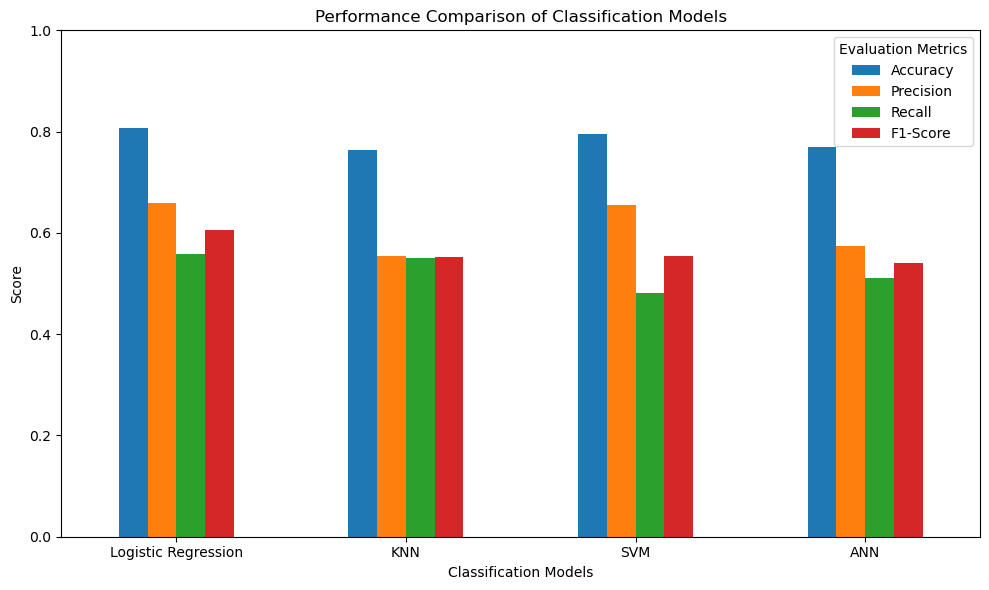

In [33]:
# Visualize model performance

comparison_plot = model_comparison.set_index("Model")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Performance Comparison of Classification Models")
plt.xlabel("Classification Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

### Model Comparison and Selection

Four classification algorithms were evaluated for the customer churn prediction task: Logistic Regression, K-Nearest Neighbors (KNN), Support Vector Machine (SVM), and Artificial Neural Network (ANN).

The models were compared using accuracy, precision, recall, and F1-score.

Logistic Regression achieved the best overall performance, recording an accuracy of 80.62%, precision of 65.93%, recall of 55.88%, and F1-score of 60.49%. It outperformed the other models across all four evaluation metrics.

Therefore, Logistic Regression was selected as the best-performing model among the four algorithms evaluated.

However, its recall score of 55.88% indicates that the model still fails to identify some customers who are likely to churn. Further optimization may improve its ability to detect potential churners.

## Logistic Regression Hyperparameter Tuning.

In [34]:
# Define the hyperparameters
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "class_weight": [None, "balanced"],
    "solver": ["lbfgs"],
    "max_iter": [1000]
}

In [35]:
# Set up GridSearchCV
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

In [36]:
# Train the tuning process
grid_search.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=LogisticRegression(random_state=42), n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 10, 100],
                         'class_weight': [None, 'balanced'], 'max_iter': [1000],
                         'solver': ['lbfgs']},
             scoring='f1')

In [37]:
# Display the best settings
print("Best Parameters:", grid_search.best_params_)

print("Best Cross-Validation F1-Score:", grid_search.best_score_)

Best Parameters: {'C': 0.1, 'class_weight': 'balanced', 'max_iter': 1000, 'solver': 'lbfgs'}
Best Cross-Validation F1-Score: 0.6300847513329656


## Train the optimized Logistic Regression model

In [38]:
# Create the model
best_log_model = grid_search.best_estimator_

In [39]:
# Train the model
best_log_model.fit(X_train, y_train)

LogisticRegression(C=0.1, class_weight='balanced', max_iter=1000,
                   random_state=42)

In [40]:
# Make prediction
y_pred_best_log = best_log_model.predict(X_test)

print(y_pred_best_log[:10])

[0 1 0 1 0 1 1 0 0 1]


In [41]:
# Evaluate the optimized model
accuracy_best_log = accuracy_score(y_test, y_pred_best_log)

print("Optimized Logistic Regression Accuracy:", accuracy_best_log)

Optimized Logistic Regression Accuracy: 0.7430801987224982


In [42]:
# Classification report
print(classification_report(y_test, y_pred_best_log))

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1035
           1       0.51      0.78      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



In [43]:
# Confusion matrix
cm_best_log = confusion_matrix(y_test, y_pred_best_log)

print(cm_best_log)

[[754 281]
 [ 81 293]]


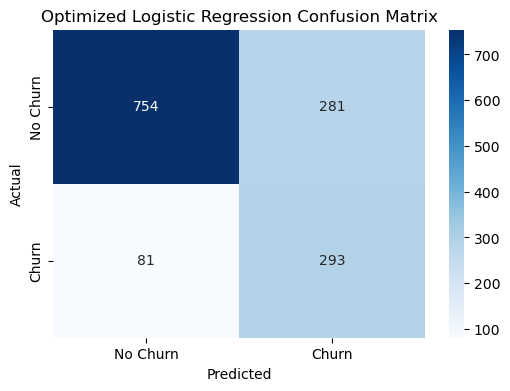

In [44]:
# Visualize the confuison matrix

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm_best_log,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Optimized Logistic Regression Confusion Matrix")

plt.show()

### Optimized Logistic Regression Model Evaluation

Hyperparameter tuning was performed on the original Logistic Regression model using GridSearchCV and five-fold stratified cross-validation. The best parameters were C = 0.1, class_weight = 'balanced', max_iter = 1000, and solver = 'lbfgs'.

The optimized model achieved an accuracy of 74.31%, with a precision of 51%, recall of 78%, and F1-score of 62% for the churn class.

The confusion matrix showed 293 true positives, 754 true negatives, 281 false positives, and 81 false negatives.

Compared with the original Logistic Regression model, the optimized model significantly improved churn recall from 55.88% to 78% and reduced false negatives from 165 to 81. However, its accuracy decreased from 80.62% to 74.31%, while false positives increased from 108 to 281.

Overall, the optimized model demonstrated a stronger ability to identify customers who are likely to churn, although this improvement came with an increase in incorrect churn predictions.

## Comparison between the original and optimized Logistic Regression models.

In [45]:
# Create a comparison table

log_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Optimized Logistic Regression"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_best_log)
    ],

    "Precision": [
        precision_score(y_test, y_pred_log),
        precision_score(y_test, y_pred_best_log)
    ],

    "Recall": [
        recall_score(y_test, y_pred_log),
        recall_score(y_test, y_pred_best_log)
    ],

    "F1-Score": [
        f1_score(y_test, y_pred_log),
        f1_score(y_test, y_pred_best_log)
    ]
})

log_comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Original Logistic Regression,0.806246,0.659306,0.558824,0.604920
1,Optimized Logistic Regression,0.743080,0.510453,0.783422,0.618143


### Comparison and Selection of Original and Optimized Logistic Regression Models

The original and optimized Logistic Regression models were compared using accuracy, precision, recall, and F1-score.

The original Logistic Regression model achieved an accuracy of 80.62%, precision of 65.93%, recall of 55.88%, and F1-score of 60.49%.

The optimized Logistic Regression model achieved an accuracy of 74.31%, precision of 51.05%, recall of 78.34%, and F1-score of 61.81%.

The comparison revealed that the original model performed better in accuracy and precision, while the optimized model achieved higher recall and F1-score.

The optimized model was selected as the preferred model for churn detection because identifying more customers who are likely to leave is an important objective of customer churn prediction. Its higher recall indicates an improved ability to detect actual churners, although this comes with more false positive predictions.